# 01 – Utforskende dataanalyse (EDA)

Livssyklus-steg: **Data → Explore data / Define data quality**.

Notatboka dokumenterer hvorfor dataene må behandles slik de gjøres i `phishcheck/` og `scripts/prepare.py`.
Den bruker bare **train**-delen av datasettet til analyse (testdelen telles bare). Kjør `python scripts/download.py` og `python scripts/prepare.py` først.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from phishcheck.canonical import canonicalize
from phishcheck.domains import host_parts
pd.set_option('display.width', 160)
raw = pd.read_parquet('../data/raw/phreshphish_urls.parquet')
data = pd.read_parquet('../data/processed/urls.parquet')
print(json.load(open('../data/MANIFEST.json'))['revision'])
raw.groupby(['split', 'label']).size().unstack()

eca603e0ecd4f698f8d4d226c088659e72681239


label,benign,phish
split,,
test,91260,76800
train,276729,221526


## 1. Klassefordeling over tid
Innsamlingen er ujevn: det finnes **ingen legitime URL-er fra november 2024 til mai 2025**. Derfor bruker vi en tidsbasert valideringssplitt og en månedsrevisjon av features.

label,benign,phish
month,,
2024-07,147,53409
2024-08,84646,15345
2024-09,75336,28668
2024-10,14874,24212
2024-11,0,15585
2024-12,0,7868
2025-01,0,23004
2025-02,0,9324
2025-03,0,5678


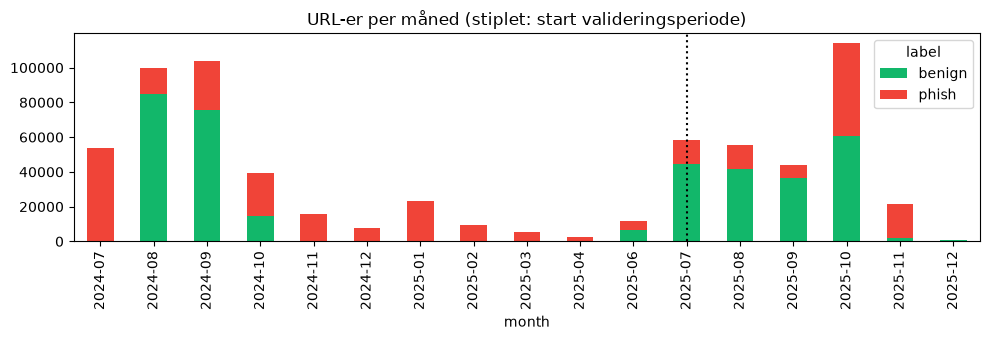

In [2]:
m = raw.assign(month=raw['date'].dt.to_period('M').astype(str)).groupby(['month', 'label']).size().unstack(fill_value=0)
ax = m.plot.bar(stacked=True, figsize=(10, 3.5), color=['#12b76a', '#f04438'])
ax.axvline(list(m.index).index('2025-07'), color='k', ls=':'); ax.set_title('URL-er per måned (stiplet: start valideringsperiode)'); plt.tight_layout()
m

## 2. Artefakter i URL-formatet (kun train-delen)
Sammenlign hvordan URL-ene er *skrevet* i de to klassene. Forskjeller som skyldes innsamlingen, ikke phishing, gir snarveier som ikke holder i virkeligheten.

In [3]:
tr = raw[raw['split'] == 'train']
u = tr['url']
audit = pd.DataFrame({
    'har query (?)': u.str.contains(r'\?', regex=True),
    'har fragment (#)': u.str.contains('#'),
    'mangler skjema': ~u.str.contains('^[A-Za-z]+://', regex=True),
    'http (ikke https)': u.str.startswith('http://'),
    'starter med www.': u.str.contains('://www\\.', regex=True),
    'slutter med /': u.str.endswith('/'),
    'tom sti (ingen /)': u.str.match(r'^[a-zA-Z]+://[^/]+$'),
    'kun forside': [canonicalize(x).is_root for x in u],
}).groupby(tr['label']).mean().T.round(3)
audit

label,benign,phish
har query (?),0.000,0.074
har fragment (#),0.000,0.007
mangler skjema,0.015,0.000
http (ikke https),0.006,0.134
starter med www.,0.577,0.039
slutter med /,0.339,0.437
tom sti (ingen /),0.000,0.058
kun forside,0.070,0.468


**Tolkning:**
- *Query/fragment*: legitime URL-er har **aldri** query-streng, trolig fordi de kommer fra anonymisert telemetri. Uten tiltak lærer modellen «`?` = phishing». Tiltak: query og fragment fjernes for alle URL-er (`canonical.py`).
- *Tom sti / skråstrek*: ingen legitime URL-er mangler `/` etter domenet, mens mange phishing-URL-er gjør det. Uten tiltak gir `nrk.no` og `nrk.no/` motsatt dom. Tiltak: skråstrek på slutten fjernes, og stien normaliseres.
- *Kun forside*: bare rundt 7 % av legitime URL-er er forsider, mot rundt 45 % av phishing. I virkeligheten er forsider til ekte nettsteder svært vanlige. Tiltak: datautvidelse med stiprefikser (`augment.py`).

## 3. Hvor phishing ligger: delte plattformer

In [4]:
core = data[data['set'] == 'core']
reg = core.assign(reg=[host_parts(h).registrable_private for h in core['host']])
top = reg.groupby('reg').agg(rows=('y', 'size'), phish_share=('y', 'mean'), hosts=('host', 'nunique'))
top.sort_values('rows', ascending=False).head(20)

,rows,phish_share,hosts
reg,,,
gitbook.io,19736,1.000000,19412
google.com,12189,0.953072,57
weeblysite.com,8429,1.000000,8383
weebly.com,7610,0.998949,7586
wikipedia.org,7073,0.000000,25
facebook.com,2100,0.001905,26
reddit.com,1835,0.000000,5
2mdn.net,1726,0.000000,1
amazon.com,1522,0.000000,29


Mange av de største phishing-kildene er **delte plattformer** (gitbook.io, weebly, webflow.io, docs.google.com) der nesten ingen legitime eksempler finnes. Det har tre konsekvenser: plattformene grupperes per vertsnavn i kryssvalideringen, appen viser et forbehold for dem, og rapporten bør diskutere det.

## 4. URL-lengde etter kanonisering

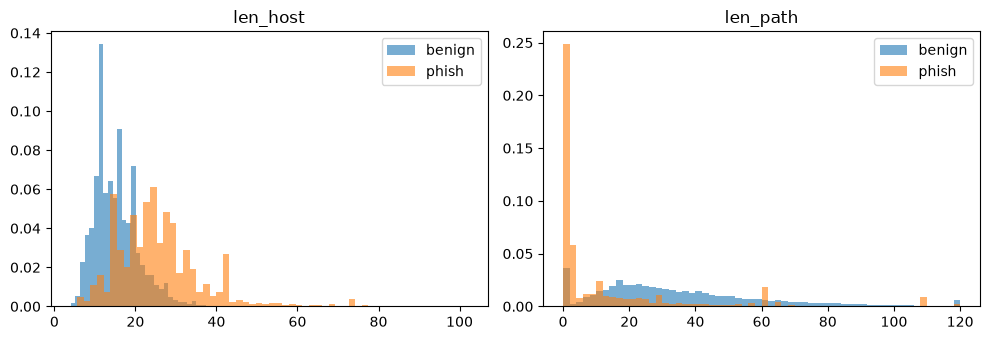

In [5]:
c = [canonicalize(x) for x in core['url']]
core = core.assign(len_host=[len(x.host) for x in c], len_path=[len(x.path) for x in c])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ['len_host', 'len_path']):
    for lab, g in core.groupby('label'):
        ax.hist(g[col].clip(upper=120), bins=60, alpha=.6, density=True, label=lab)
    ax.set_title(col); ax.legend()
plt.tight_layout()

## 5. Månedsrevisjon av features
Resultat fra `scripts/audit_months.py`: standardisert forskjell *d* (phishing minus legitim) per måned. Features der fortegnet skifter (|d| ≥ 0,2 i begge retninger) er fjernet.

['entropy_domain', 'len_domain']


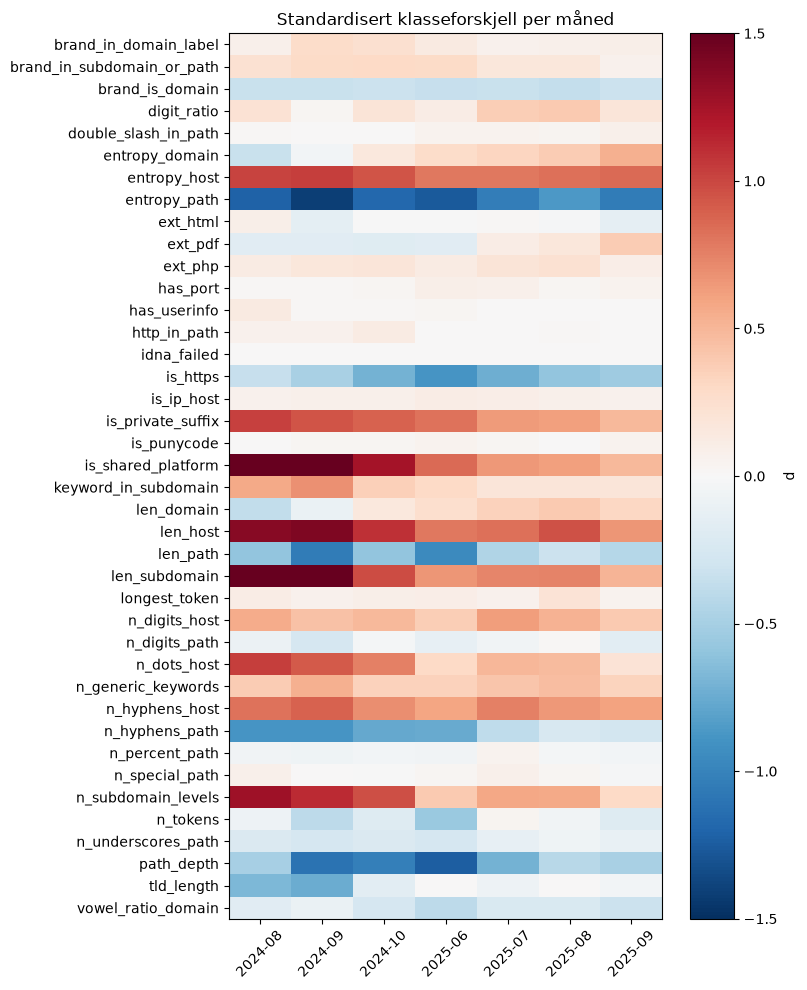

In [6]:
audit_m = pd.read_csv('../reports/month_audit.csv', index_col=0)
print(json.load(open('../reports/month_audit.json'))['flagged_features'])
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(audit_m.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_yticks(range(len(audit_m))); ax.set_yticklabels(audit_m.index); ax.set_xticks(range(audit_m.shape[1])); ax.set_xticklabels(audit_m.columns, rotation=45)
plt.colorbar(im, label='d'); ax.set_title('Standardisert klasseforskjell per måned'); plt.tight_layout()

## 6. Rensing og datautvidelse – oppsummering

In [7]:
summary = json.load(open('../reports/data_summary.json'))
{k: summary[k] for k in ['shortener_rows_by_split_label', 'train_rows_dropped_duplicate', 'test_rows_dropped_seen_in_train', 'rows_by_set_label', 'phish_share_by_set']}

{'shortener_rows_by_split_label': {'test/benign': 1,
  'test/phish': 205,
  'train/benign': 1,
  'train/phish': 6614},
 'train_rows_dropped_duplicate': 4192,
 'test_rows_dropped_seen_in_train': 31,
 'rows_by_set_label': {'core': {'benign': 181721, 'phish': 181550},
  'test': {'benign': 91199, 'phish': 72295},
  'val': {'benign': 94901, 'phish': 29274}},
 'phish_share_by_set': {'core': 0.4998, 'test': 0.4422, 'val': 0.2357}}

In [8]:
from phishcheck.datasets import training_frame
tf = training_frame(data[data['set'] == 'core'])
roots = [canonicalize(x).is_root for x in tf['url']]
tf.assign(is_root=roots).groupby(['y', 'is_augmented'])['is_root'].agg(['size', 'mean']).rename(columns={'size': 'rader', 'mean': 'andel forsider'})

rader  andel forsider
y is_augmented                        
0 False         181721        0.071912
  True          235710        0.294455
1 False         181550        0.496596

Etter utvidelsen er forsider og korte stier representert blant legitime URL-er. Hosts med phishing i treningsdataene og delte plattformer er **ikke** utvidet, fordi antagelsen «prefiks av legitim side = legitim» ikke holder der.